# Porter NN Regression: Environment Check
Smoke test: imports, a random forest baseline and a small Keras network on synthetic data. Works locally and in Google Colab.

In [1]:
import sys, numpy as np, pandas as pd, sklearn, matplotlib, seaborn as sns
import tensorflow as tf
import matplotlib.pyplot as plt
print('python', sys.version.split()[0])
for m in (np, pd, sklearn, matplotlib, sns, tf):
    print(m.__name__, m.__version__)

python 3.13.18
numpy 2.5.5
pandas 3.1.1
sklearn 1.9.1
matplotlib 3.11.2
seaborn 0.13.2
tensorflow 2.21.0


## Synthetic data (stand-in for the Porter dataset)

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
rng = np.random.default_rng(42)
X = rng.normal(size=(2000, 6))
y = 30 + 5*X[:,0] - 3*X[:,1] + 2*X[:,2]**2 + rng.normal(scale=1.0, size=2000)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(1600, 6) (400, 6)


## Baseline: Random Forest

In [3]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1).fit(X_train, y_train)
p = rf.predict(X_test)
rf_res = dict(MSE=mean_squared_error(y_test,p), RMSE=mean_squared_error(y_test,p)**0.5, MAE=mean_absolute_error(y_test,p), R2=r2_score(y_test,p))
print(rf_res)

{'MSE': 2.872516329974891, 'RMSE': 1.6948499432029052, 'MAE': 1.1916224922088665, 'R2': 0.9312969511440594}


## Neural network (Keras)

In [4]:
scaler = StandardScaler().fit(X_train)
Xs_train, Xs_test = scaler.transform(X_train), scaler.transform(X_test)
# Scale the target too: the network's output starts near 0
y_scaler = StandardScaler().fit(y_train.reshape(-1, 1))
ys_train = y_scaler.transform(y_train.reshape(-1, 1)).ravel()
tf.keras.utils.set_random_seed(42)
model = tf.keras.Sequential([
    tf.keras.Input(shape=(Xs_train.shape[1],)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(1)])
model.compile(optimizer='adam', loss='mse', metrics=['mae'])
hist = model.fit(Xs_train, ys_train, validation_split=0.2, epochs=30, batch_size=64, verbose=0)
p = y_scaler.inverse_transform(model.predict(Xs_test, verbose=0)).ravel()
nn_res = dict(MSE=mean_squared_error(y_test,p), RMSE=mean_squared_error(y_test,p)**0.5, MAE=mean_absolute_error(y_test,p), R2=r2_score(y_test,p))
print(nn_res)

{'MSE': 1.8975362190915523, 'RMSE': 1.3775108780302072, 'MAE': 1.083385483873351, 'R2': 0.9546159155978399}


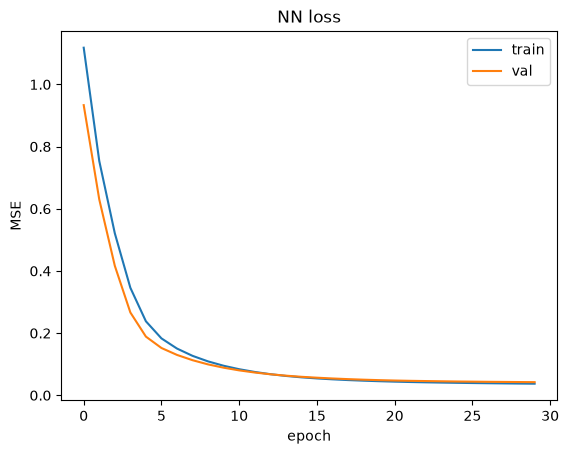

      RandomForest  NeuralNet
MSE          2.873      1.898
RMSE         1.695      1.378
MAE          1.192      1.083
R2           0.931      0.955
ALL CHECKS PASSED


In [5]:
plt.plot(hist.history['loss'], label='train'); plt.plot(hist.history['val_loss'], label='val')
plt.xlabel('epoch'); plt.ylabel('MSE'); plt.legend(); plt.title('NN loss'); plt.show()
print(pd.DataFrame({'RandomForest': rf_res, 'NeuralNet': nn_res}).round(3))
assert rf_res['R2'] > 0.8 and nn_res['R2'] > 0.8
print('ALL CHECKS PASSED')

## Extra package checks
PyTorch, torchvision, scikit-image, LIME and ipywidgets, matching the packages used across the `nn_day_*` notebooks.

### PyTorch: small regression network

In [6]:
import torch, torch.nn as nn
torch.manual_seed(42)
Xt_train = torch.tensor(Xs_train, dtype=torch.float32)
yt_train = torch.tensor(ys_train, dtype=torch.float32).unsqueeze(1)
Xt_test = torch.tensor(Xs_test, dtype=torch.float32)
net = nn.Sequential(nn.Linear(6, 32), nn.ReLU(), nn.Linear(32, 16), nn.ReLU(), nn.Linear(16, 1))
opt = torch.optim.Adam(net.parameters(), lr=1e-2)
loss_fn = nn.MSELoss()
for epoch in range(100):
    opt.zero_grad()
    loss = loss_fn(net(Xt_train), yt_train)
    loss.backward()
    opt.step()
with torch.no_grad():
    p_torch = y_scaler.inverse_transform(net(Xt_test).numpy()).ravel()
torch_res = dict(RMSE=mean_squared_error(y_test, p_torch)**0.5, R2=r2_score(y_test, p_torch))
print('torch', torch.__version__, '| device:', 'mps' if torch.backends.mps.is_available() else 'cpu', '|', torch_res)
assert torch_res['R2'] > 0.8

torch 2.15.0 | device: mps | {'RMSE': 1.1573914112451777, 'R2': 0.9679613642837427}


### torchvision: transforms and a model built offline (no downloads)

In [7]:
import torchvision, torchvision.transforms as T
from torchvision.models import resnet18
tfm = T.Compose([T.ToTensor(), T.Normalize((0.5,), (0.5,))])
img = (np.random.default_rng(0).random((28, 28)) * 255).astype('uint8')
x = tfm(img)
model_tv = resnet18(weights=None, num_classes=10)
out = model_tv(torch.randn(2, 3, 64, 64))
print('torchvision', torchvision.__version__, '| transformed:', tuple(x.shape), '| resnet18 out:', tuple(out.shape))
assert out.shape == (2, 10)

torchvision 0.29.2 | transformed: (1, 28, 28) | resnet18 out: (2, 10)


### scikit-image: segmentation

In [8]:
import skimage
from skimage.segmentation import slic
from skimage.data import astronaut
im = astronaut()[::4, ::4]
segs = slic(im, n_segments=20, start_label=0)
print('scikit-image', skimage.__version__, '| segments found:', len(np.unique(segs)))
assert len(np.unique(segs)) > 1

scikit-image 0.26.0 | segments found: 7


### LIME: explain one random forest prediction

In [9]:
# Colab does not ship lime; harmless if already installed
!pip install -q lime

In [10]:
from lime.lime_tabular import LimeTabularExplainer
names = [f'x{i}' for i in range(X_train.shape[1])]
explainer = LimeTabularExplainer(X_train, feature_names=names, mode='regression', random_state=42)
exp = explainer.explain_instance(X_test[0], rf.predict, num_features=3)
print('LIME top features:', exp.as_list())
assert len(exp.as_list()) == 3

LIME top features: [('x1 > 0.64', -5.701373478747906), ('-0.67 < x0 <= -0.03', -1.8175219541365013), ('x2 <= -0.73', 1.7718877312810353)]


### ipywidgets

In [11]:
import ipywidgets as widgets
w = widgets.IntSlider(value=5, min=0, max=10, description='epochs')
print('ipywidgets', widgets.__version__, '| slider value:', w.value)
w

ipywidgets 8.1.9 | slider value: 5


IntSlider(value=5, description='epochs', max=10)

In [12]:
print('EXTRA CHECKS PASSED')

EXTRA CHECKS PASSED


### TPU check (Colab TPU runtime only)
Confirms JAX sees the TPU and runs a matrix multiply on it. On a CPU/GPU runtime or locally it prints a skip message instead of failing.

In [13]:
try:
    import time, jax, jax.numpy as jnp
    devs = jax.devices()
    print('jax', jax.__version__, '| devices:', devs)
    if devs[0].platform != 'tpu':
        print('SKIPPED: no TPU attached (runtime is', devs[0].platform + ')')
    else:
        x = jnp.ones((4096, 4096), dtype=jnp.bfloat16)
        f = jax.jit(lambda a: a @ a)
        f(x).block_until_ready()              # compile / warm-up
        t = time.time()
        for _ in range(10):
            y = f(x)
        y.block_until_ready()
        dt = (time.time() - t) / 10
        print(f'matmul 4096x4096 on {y.devices()} | {dt*1000:.2f} ms/iter | y[0,0]={float(y[0,0])}')
        assert float(y[0, 0]) == 4096.0
        print('TPU CHECK PASSED')
except ImportError:
    print('SKIPPED: jax not installed (expected in the local venv)')

SKIPPED: jax not installed (expected in the local venv)


In [14]:
import sys, platform
print(sys.version.split()[0], platform.node(), sys.executable)

3.13.18 W45WVV09N1 /Users/vinayakkumar.udikeri/Documents/Porter_NN_Regression/venv/bin/python
